# **How many people are in the room?** 

In this notebook, we use the dataset: Room Occupancy Estimation from UCI ML datasets. This datasets provides us with sensors information (light, sound, CO2 concentration...) and the number of people inside the room where these measures are taken.

We are a big company, and want to ventilate our offices. We have 4 ventilation power, each one adapted to how many people are in the room. Our goal is to predict how many people are in the room to then activate the correct ventilation level. Like this, we economise power when ventilation is not needed: we are more green and lose less money !!

We want to answer it with sensor data only

1. We load the data and look at it
2. We check the quality of the data , if it has any missing values or duplicates
3. We look at the target: how many people are in the room, and how often
4. We split the data into three parts (train, validation, test), in time order
5. We define the decision (how much to ventilate) and its costs
6. We define how we measure performance
7. We compute two baselines
8. We build four tree candidates: all sensors (A), aggregated sensors (B), forward feature selection (C), LASSO feature selection (D)
9. Compare them on validation and save our models
10. Evaluate once on the test
11. Extra analyses: cost sensitivity and selection stability
12. Recommendation and limitations

## **IMPORTS**

In [36]:
import json
import numpy as np                      
import pandas as pd                    
import matplotlib.pyplot as plt        
from sklearn.metrics import accuracy_score,f1_score   
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import Lasso
from sklearn.metrics import confusion_matrix
import os

# colors and plot style
BLUE, ORANGE, INK, GREY = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,   
                     "axes.grid": True, "grid.color": "#e6e5e1", "figure.dpi": 110})

# 1 - Loading the data

In [37]:
# download the dataset from UCI ML repository 
DATA_URL = "https://archive.ics.uci.edu/static/public/864/room+occupancy+estimation.zip"

if not os.path.exists("Occupancy_Estimation.csv"):
    pd.read_csv(DATA_URL).to_csv("Occupancy_Estimation.csv", index=False)

In [38]:
df = pd.read_csv("Occupancy_Estimation.csv")   

print("Number of rows:",df.shape[0])
print("Number of columns:",df.shape[1])
df.head(300)    

Number of rows: 10129
Number of columns: 19


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,2017/12/22,13:49:25,26.06,27.06,26.00,26.38,164,254,276,70,0.30,0.26,0.64,0.08,910,1.661538,1,1,3
296,2017/12/22,13:49:55,26.06,27.00,26.00,26.31,165,254,275,70,0.83,0.27,0.62,0.14,910,1.553846,1,1,3
297,2017/12/22,13:50:26,26.06,27.00,26.00,26.31,164,254,274,70,1.20,0.28,0.22,0.11,910,1.446154,1,1,3
298,2017/12/22,13:50:56,26.13,27.06,26.00,26.31,165,254,274,71,1.13,1.40,1.51,1.36,910,1.392308,1,1,3


**What we see:** 10129 rows and 19 columns

- `Date`and`Time`: when the measure was taken
- 16 sensor columns:
  - From `S1_Temp` to `S4_Temp`: temperature, in celsius
  - From `S1_Light` to `S4_Light`: light, in lux
  - From `S1_Sound` to `S4_Sound`: sound, in volts
  - From `S5_CO2`: CO2 in the air, in ppm (parts per million)
  - From `S5_CO2_Slope`: how fast CO2 goes up or down
  - From `S6_PIR`, `S7_PIR`: motion detectors (1 = movement detected, 0 = no mvmt)
- `Room_Occupancy_Count`: **the target**, the number of people, from 0 to 3. It was written down by hand

In [39]:
# We put date and time together into only one real timestamp, so we can sort and cut the data by time
df["ts"] =pd.to_datetime(df["Date"]+" "+df["Time"])

# Check: are the rows already in time order?
print("Rows are in time order:", df["ts"].is_monotonic_increasing)

TARGET = "Room_Occupancy_Count" #name of the target column                           
features =[c for c in df.columns if c.startswith("S")]     # the 16 sensor columns
print(len(features),"sensor variables:",features)

Rows are in time order: True
16 sensor variables: ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']


# 2 - Check the quality of the data

Before we use the data, we check two common problems: missing values & duplicates

In [40]:
print("Missing values in the whole table :",int(df.isna().sum().sum()))   # count empty cells
print("Duplicated rows :",int(df.duplicated().sum()))                      # count repeated rows

Missing values in the whole table : 0
Duplicated rows : 0


We see that there are no missing values and no duplicates (blessed scenario). So we do not need to fill in or remove anything

### Summary of the 16 sensor variables
For each sensor we show its unit, its mean, its standard deviation (how much it varies), its minimum and its maximum

In [41]:
units = ["°C"] * 4 + ["lux"] * 4 + ["V"] * 4 + ["ppm", "ppm per step", "0/1", "0/1"]
summary = df[features].describe().T[["mean", "std", "min", "max"]].round(2)   # .T turns the table so each sensor is a row
summary.insert(0, "unit", units)                                                # add the unit as the first column
summary

,unit,mean,std,min,max
S1_Temp,°C,25.45,0.35,24.94,26.38
S2_Temp,°C,25.55,0.59,24.75,29.00
S3_Temp,°C,25.06,0.43,24.44,26.19
S4_Temp,°C,25.75,0.36,24.94,26.56
S1_Light,lux,25.45,51.01,0.00,165.00
S2_Light,lux,26.02,67.30,0.00,258.00
S3_Light,lux,34.25,58.40,0.00,280.00
S4_Light,lux,13.22,19.60,0.00,74.00
S1_Sound,V,0.17,0.32,0.06,3.88
S2_Sound,V,0.12,0.27,0.04,3.44


# 3 - Look at the target (the number of people)

In [42]:
counts = df[TARGET].value_counts().sort_index()        # how many rows for 0,1,2, 3 people
shares = (counts / len(df) * 100).round(1)             # same in percent
pd.DataFrame({"rows": counts, "percent": shares})

,rows,percent
Room_Occupancy_Count,,
0,8228,81.2
1,459,4.5
2,748,7.4
3,694,6.9


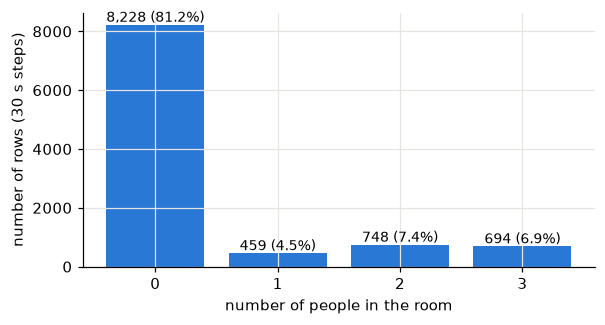

In [43]:
# Bar chart of the target
fig,ax = plt.subplots(figsize=(6, 3))
ax.bar(counts.index, counts.values, color=BLUE)
for x, n, p in zip(counts.index, counts.values, shares.values):
    ax.text(x, n + 100, f"{n:,} ({p}%)",ha="center", fontsize=9)   # writing the number above each bar
ax.set_xticks([0,1,2,3])
ax.set_xlabel("number of people in the room")
ax.set_ylabel("number of rows (30 s steps)")
plt.show()

The room is empty most of the time. It is empty 81% of the time so only about 19% of the rows have people.

This is important: a  model that always answers 0 people is already right 81% of the time.
So accuracy alone is not a good way to judge our models, we will also use other measures.

In [44]:
# when were people in the room? We look at the number of rows per day and per headcount
pd.crosstab(df["Date"], df[TARGET])

Room_Occupancy_Count,0,1,2,3
Date,,,,
2017/12/22,637,205,257,363
2017/12/23,1997,254,398,130
2017/12/24,1064,0,0,0
2017/12/25,1716,0,0,0
2017/12/26,1063,0,0,0
2018/01/10,703,0,93,201
2018/01/11,1048,0,0,0


People are present only on 3 dates: 22 Dec, 23 Dec and 10 Jan
The other days are nights or holidays with an empty room

### Are some sensors redundant?
We compute the **correlation** between sensors. A correlation close to 1 means that two sensors move together,
so they give almost the same information

In [45]:
# The training rows are the ones before 23 Dec 2017, 15:00 (I explain this choice just in the part below)
train_rows =df[df["ts"]<pd.Timestamp("2017-12-23 15:00")]
corr =train_rows[features].corr()# correlation between every pair of sensors

def mean_abs_corr(cols):
    """Average absolute correlation between the sensors in `cols` (each pair counted once)"""
    c = corr.loc[cols, cols].abs().values
    return c[np.triu_indices(len(cols), 1)].mean()     # take only the pairs above the diagonal

print("Light sensors, mean|correlation|:", round(mean_abs_corr(features[4:8]), 2))
print("Temperature sensors, mean|correlation|:", round(mean_abs_corr(features[0:4]), 2))

Light sensors, mean|correlation|: 0.69
Temperature sensors, mean|correlation|: 0.85


The 4 light sensors and the 4 temperature sensors are strongly correlated, which makes sense since they measure similar things. 
However, predicting with highly correlated variables will bias and break our model, as we have seen in lecture 4 and 5. 
This is why we will compute **variable selection** afterwards.

# 4 - Split the data in time order

We need three groups of rows:
- **train**: to fit (=learn) the models;
- **validation**: to choose between models and settings;
- **test**: to check the final model **only once**, at the end

**Why not a random split?** Two rows 30 seconds apart are almost the same. With a random split, a row in the test setwould have its "twin" in the training set. The model would look very good, but only because it has already seen almost the same moment. So we cut the data **by time**:

| Part | Period | Why |
|---|---|---|
| train | 22 Dec 10:49 → 23 Dec 15:00 | first day and a half, all headcounts 0–3 |
| validation | 23 Dec 15:00 → 24 Dec | rest of the December weekend, all headcounts 0–3 |
| test | 25 Dec → 11 Jan | Christmas (empty) + a new session two weeks later: like real use |

The first cut (23 Dec, 15:00) is in a lunch break when the room is empty, so we do not cut a session in two

In [46]:
CUT1 =pd.Timestamp("2017-12-23 15:00")   # end of train and start of validation
CUT2 =pd.Timestamp("2017-12-25 00:00")   # end of validation and start of test

#give each row a label: "train", "val" or "test"
df["split"] = np.where(df["ts"]<CUT1, "train",
                       np.where(df["ts"]< CUT2, "val","test"))

# X = the 16 sensor values (inputs),y = the number of people (target),for each part
Xtr, ytr = df.loc[df.split == "train",features],df.loc[df.split =="train", TARGET].to_numpy()
Xva, yva = df.loc[df.split == "val",features],df.loc[df.split =="val", TARGET].to_numpy()
Xte, yte = df.loc[df.split == "test",features], df.loc[df.split =="test", TARGET].to_numpy()

#number of rows per part and per headcount iin a table
split_table = pd.crosstab(df["split"], df[TARGET]).reindex(["train", "val", "test"])
split_table["total"] = split_table.sum(axis=1)
split_table

Room_Occupancy_Count,0,1,2,3,total
split,,,,,
train,2103,321,413,363,3200
val,1595,138,242,130,2105
test,4530,0,93,201,4824


We will talk about the limitations of the test split in the report, such has having no test row for exactly 1 person.

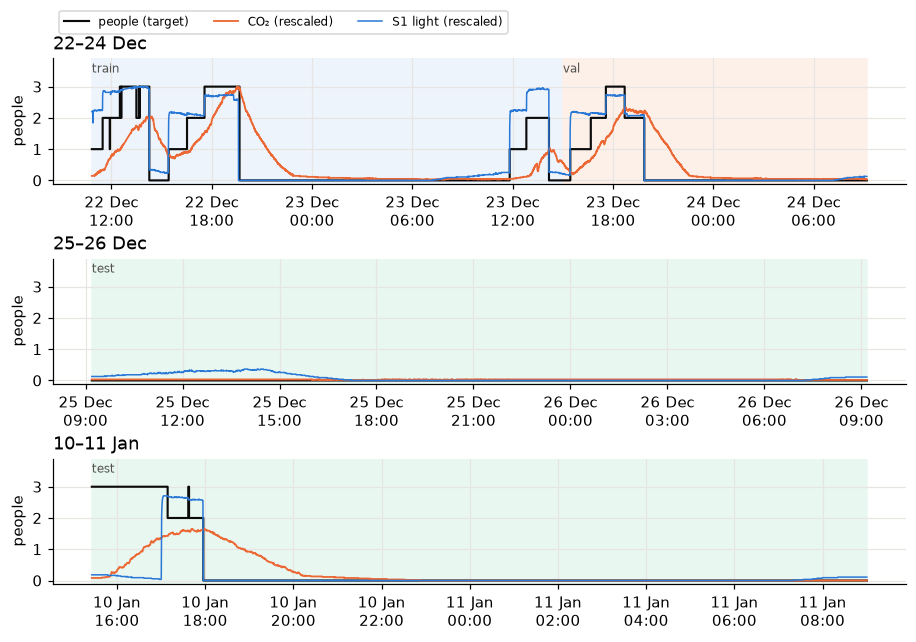

In [47]:
# Plot: the number of people over time, with the three parts in colour
# We draw one panel per recording block, because there is a gap of two weeks in the data
fig, axes = plt.subplots(3, 1, figsize=(10, 6.2), gridspec_kw={"hspace": 0.6})
blocks = [("22–24 Dec", df.ts<pd.Timestamp("2017-12-24 12:00")),
          ("25–26 Dec", (df.ts>=pd.Timestamp("2017-12-25")) & (df.ts < pd.Timestamp("2017-12-27"))),
          ("10–11 Jan", df.ts>=pd.Timestamp("2018-01-01"))]
for ax, (name, rows) in zip(axes, blocks):
    d = df[rows]
    for part, colour in (("train", "#eef4fc"),("val", "#fdf0e9"),("test", "#e9f7f1")):
        dp = d[d.split == part]
        if len(dp):  # colour the background of each part
            ax.axvspan(dp.ts.min(), dp.ts.max(), color=colour, zorder=0)
            ax.text(dp.ts.min(), 3.45, part, color=GREY, fontsize=8)
    ax.step(d.ts, d[TARGET], where="post", color=INK, lw=1.4, label="people (target)")
    # two sensors, rescaled to the 0–3 axis so we can compare their shape with the target
    ax.plot(d.ts, 3 * (d.S5_CO2 - df.S5_CO2.min()) / (df.S5_CO2.max() - df.S5_CO2.min()), color=ORANGE, lw=1.2, label="CO₂ (rescaled)")
    ax.plot(d.ts, 3 * d.S1_Light/df.S1_Light.max(), color=BLUE, lw=1.0, label="S1 light (rescaled)")
    ax.set_ylim(-0.1, 3.9); ax.set_yticks([0, 1, 2, 3]); ax.set_ylabel("people")
    ax.set_title(name, loc="left")
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b\n%H:%M"))
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.15), ncol=3, fontsize=8)
plt.show()

**Other preprocessing choices:**
- We do not use Date and Time as inputs, they describe the schedule, not the room. Besides they could add noise to our prediction, since some sensors could have higher values on a specific date (more light if it is sunnier that day). A real system must work on any day
- We do not re-balance the classes, as we deal with the imbalance through the metric and the costs 

# 5 - The decision and its costs

Knowing the number of people allow us to take the correct **decision**: how much fresh air to send into the room.

- **Action** **a** = ventilation level,from 0 to 3. Level **a** gives enough air for **a** people.
- If we ventilate **too much**, we waste energy: each level costs **1**.
- If we ventilate **too little**, people breathe bad air (more CO₂): each person without enough air costs **2**.

So the cost (our loss function) of choosing level **a** when there are really **y** people is:

$$L(a, y) = 1 \times a + 2 \times \max(y - a,\ 0)$$

We chose the cost of each action (1 and 2) by ourselves, on the assumption that missing air for one person is twice as worse than wasting one level of energy.

In [48]:
CLASSES = np.array([0, 1, 2, 3])     # possible headcounts, and also possible ventilation levels
C_E, C_U = 1.0, 2.0                  # C_E = energy cost per level, C_U = cost per person without enough air

def loss_matrix(c_e=C_E, c_u=C_U):
    """Table of costs: one row per action a (from 0 to 3), one column per true headcount y (0 to 3)"""
    a, y = np.meshgrid(CLASSES, CLASSES, indexing="ij")   # all pairs (a, y)
    return c_e * a + c_u * np.maximum(y - a, 0)

LOSS = loss_matrix()
pd.DataFrame(LOSS, index=[f"action a={a}" for a in CLASSES], columns=[f"person y={y}" for y in CLASSES])

,person y=0,person y=1,person y=2,person y=3
action a=0,0.0,2.0,4.0,6.0
action a=1,1.0,1.0,3.0,5.0
action a=2,2.0,2.0,2.0,4.0
action a=3,3.0,3.0,3.0,3.0


We see that in each column of the table, the smallest cost is on the diagonal, so if we knew the true headcount y, the best action would always be a = y.

We are building a model that will estimate the number of people. However, based on this model, we want to take an action. Our model will give a probability to each headcount. So, for each possible action, we have to compute the **expected cost** (the average cost weigthed by the probabilities of how each headcount) so that we can pick the action with the **lowest expected cost**.

This gives a simple rule: **ventilate for at least k people as soon as P(k people or more) > 1/2 = 0.5**. Why 1/2? Going one level up always costs 1, and saves 2 only if there are really more people. So it is worth it when that probability is at least 1/2. Our tie rule, so when P(k or more is) exactly 1/2, two actions have the same expected cost, is to keep the lower ventilation level.

In [49]:
def action(P, L=LOSS):
    """For each row of probabilities P, return the action with the lowest expected cost"""
    expected_cost = P @ L.T                 # expected cost of each action,for each row
    return np.argmin(expected_cost, axis=1) # index of the cheapest action (if equal, the lower level wins)

# small ex with 3 rows of probabilities for 0, 1, 2, 3 people
P_example = np.array([[0.40, 0.30, 0.20, 0.10], # P(1 or more) = 0.6 > 0.5 -> level 1
                      [0.70, 0.15, 0.10, 0.05],  # P(1 or more) = 0.3 < 0.5 ->level 0
                      [0.10, 0.10, 0.20, 0.60]])   # P(3) = 0.6 > 0.5 -> level 3
print("Chosen ventilation levels:", action(P_example))   # expected:[1 0 3]

Chosen ventilation levels: [1 0 3]


The result `[1 0 3]` matches the rule. Note the first row: the most likely answer is 0 people with 40% prob, but the rule still ventilates at level 1, because forgetting a person is more expensive

# 6 - How we measure performance

We use these measures in the whole project:

- **Mean cost**: the average of L(a, y) over all rows
- **Regret** = mean cost − cost with perfect information. "Perfect information" means we always know the true headcount and choose a = y, regret 0 is perfect. We use regret because the three parts (train, validation, test) do not have the same number of people, so their raw costs cannot be compared directly
  
  -> This is the metric we will use to tune our models: the loss to minimise
- **Macro-F1**: the F1 score for each headcount, then the average of the four, each headcount counts the same, even the rare ones. This is better than accuracy here
- **Accuracy**: share of correct predictions, we show it only for reference

In [50]:
def mean_cost(actions, y, L=LOSS):
    """Average cost of the chosen actions, given the true nb of people y"""
    return float(L[actions, y].mean())

def oracle_cost(y, L=LOSS):
    """cost if we always knew the truth (action = true nb of people), no policy can do better"""
    return float(L[y, y].mean())

def scores(y, predicted_count, actions):
    """summary"""
    return {"accuracy": accuracy_score(y, predicted_count),
            "macro_F1": f1_score(y, predicted_count, average="macro", zero_division=0),
            "mean_cost": mean_cost(actions, y),
            "regret": mean_cost(actions, y) - oracle_cost(y)}


for name, y in (("train", ytr), ("validation", yva), ("test", yte)):
    print(f"Perfect-information cost on {name}: {oracle_cost(y):.3f}")

Perfect-information cost on train: 0.699
Perfect-information cost on validation: 0.481
Perfect-information cost on test: 0.164


# 7 - The baselines

A baseline is a very simple policy with no learning. A real model is only useful if it beats it. We use two:

1. **Never ventilate** (always predict 0 people). This is also the "majority class" classifier, because 0 is the most common answer. It saves all the energy, but it forgets every person
2. **Always ventilate for 3 people.** Nobody ever lacks air, but we waste energy all the time

We measure them on the **validation** part

In [51]:
never = np.zeros_like(yva)        # action 0 for every row
always3 =np.full_like(yva, 3)    # action 3 for every row

baselines =pd.DataFrame({
    "Never ventilate (always predict 0)": scores(yva, never, never),
    "Always ventilate for 3": scores(yva, always3, always3),
}).T
baselines.round(3)

,accuracy,macro_F1,mean_cost,regret
Never ventilate (always predict 0),0.758,0.216,0.962,0.481
Always ventilate for 3,0.062,0.029,3.000,2.519


# 8 - Decision Models

## 8.1 - Decision tree function

Here, we have a classification problem (4 outputs level). Therefore we want to have a classification model, and are thus building a **decision tree**
All our candidates use the same model: a **decision tree**. A tree gives a probability for each headcount, so we can use the action function we built before.

We want to build 4 different types of decision tree, our 4 candidates, to check which one performs better on our validation. 
Since they are all decision trees, we decided to build a general decision tree function.

For every candidate we try the same grid of settings:
- max_depth (how many questions the tree can ask) in [1, 2, 3, 4, 5, 6, 8, 10]
- min_samples_leaf (smallest number of rows in a final leaf) in [1, 5, 10, 20, 50]

Each tree is **fitted on train** and **judged on validation** with the regret. If two trees have the same regret, we keep the simplest one: smaller depth first, then bigger leaves.

In [ ]:
DEPTHS = [1, 2, 3, 4, 5, 6, 8, 10]
LEAVES = [1, 5, 10, 20, 50]

def tree_proba(tree, X):
    return tree.predict_proba(X)
def tree_proba(tree, X):
    """Computes the probas of the tree in the order of CLASSES """
    P = np.zeros((len(X), len(CLASSES)))
    P[:, tree.classes_] = tree.predict_proba(X)
    return P


def evaluate(tree, X, y):
    """Computes the scores of the tree, st predicted count = most likely class, action = action"""
    P = tree_proba(tree, X)
    return scores(y, CLASSES[P.argmax(axis=1)], action(P))

def tune_tree(Xa, Xb):
    """Fit one tree per setting on train (Xa) and keep the one with the lowest regret on validation (Xb)"""
    rows = []
    for d in DEPTHS:
        for m in LEAVES:
            tree = DecisionTreeClassifier(max_depth=d, min_samples_leaf=m, random_state=0).fit(Xa, ytr)
            rows.append({"max_depth": d, "min_samples_leaf": m, **evaluate(tree, Xb, yva)})
    grid = pd.DataFrame(rows)
    grid["regret_r"] = grid["regret"].round(10)   # rounding to not take into account tiny differences which are an issue with deep trees
    # lowest regret, then smaller depth, then bigger min_samples_leaf (as we said earlier in our explaination)
    best = grid.sort_values(["regret_r", "max_depth", "min_samples_leaf"], ascending=[True, True, False]).iloc[0]
    params = {"max_depth": int(best["max_depth"]), "min_samples_leaf": int(best["min_samples_leaf"])}
    best_tree = DecisionTreeClassifier(**params, random_state=0).fit(Xa, ytr)
    return best_tree, params, grid.drop(columns="regret_r")


## 8.2 - Candidate A: a tree on the 16 raw sensors

Our first candidate is a tree on the raw features.
We give the tree all 16 sensors, without any change in the features


In [53]:
cols_A = list(features)
tree_A, params_A, grid_A = tune_tree(Xtr[cols_A], Xva[cols_A])
print("Best settings for A:", params_A)
grid_A.sort_values("regret").head(5).round(3)   

Best settings for A: {'max_depth': 4, 'min_samples_leaf': 1}


,max_depth,min_samples_leaf,accuracy,macro_F1,mean_cost,regret
20,5,1,0.983,0.945,0.497,0.017
35,10,1,0.983,0.945,0.497,0.017
15,4,1,0.983,0.945,0.497,0.017
25,6,1,0.983,0.945,0.497,0.017
30,8,1,0.983,0.945,0.497,0.017


The best tree has a maximum depth of 4 and a minimum of 1 row per leaf. On the validation set, its most likely class is correct for 98.3% of the rows, and its macro-F1 is 0.945. This means the tree also separates the rare headcounts well, not only the empty room. Its mean cost is 0.497 is close to the perfect-information cost of 0.481. Its regret is therefore only 0.017, against 1.442 for “never ventilate” and 2.519 for “always ventilate for 3”.
We see that depths 4 to 10 give exactly the same scores, which at first can appear quite strange. This probably means that the tree already separates the training data perfectly at depth 4, so deeper trees add no new splits, and no new information. Our tie rule then keeps the simplest tree, with depth 4. 

One important limit to these very encouraging results is the validation set: since it covers only one afternoon right after the training period, its result is probably optimistic. More realistic performance measures will probably come out of our test set with values 2 weeks later.

Something else we found strange is that the best trees all have the same min_samples_leaf. Thus we want to check the actual size of the leaves of our selected tree.

In [54]:
leaf_sizes = pd.Series(tree_A.apply(Xtr[cols_A])).value_counts().sort_values()
print(leaf_sizes)

3        2
14       3
17      20
10      28
8       32
18      40
7      281
15     298
11     393
2     2103
Name: count, dtype: int64


So we have only 2 leaves necesitating the min_sample_leaf to be set to 1. Let's check how many rows of each class go to each leaf.

In [55]:
leaves_tr = tree_A.apply(Xtr[cols_A]) # how many training rows in each leaf
print(pd.crosstab(leaves_tr, ytr))

leaves_va = tree_A.apply(Xva[cols_A]) # how many validation rows
print(pd.Series(leaves_va).value_counts())

col_0     0    1    2    3
row_0                     
2      2103    0    0    0
3         0    0    0    2
7         0  281    0    0
8         0    0   32    0
10        0   28    0    0
11        0   12  359   22
14        0    0    3    0
15        0    0    3  295
17        0    0   15    5
18        0    0    1   39
2     1594
7      139
11     139
14     137
15      96
Name: count, dtype: int64


Here we see that in leaf 2 we have all the empty rooms, which is a very interesting result. 

Something else we can notice is leaf 14. In the training it only takes 3 rows, so it needs the min_sample_leaf to be 1 and not any of the upper groups. In the validation it takes 137 rows, so it contributes to the low regret score, explaining the ranking.

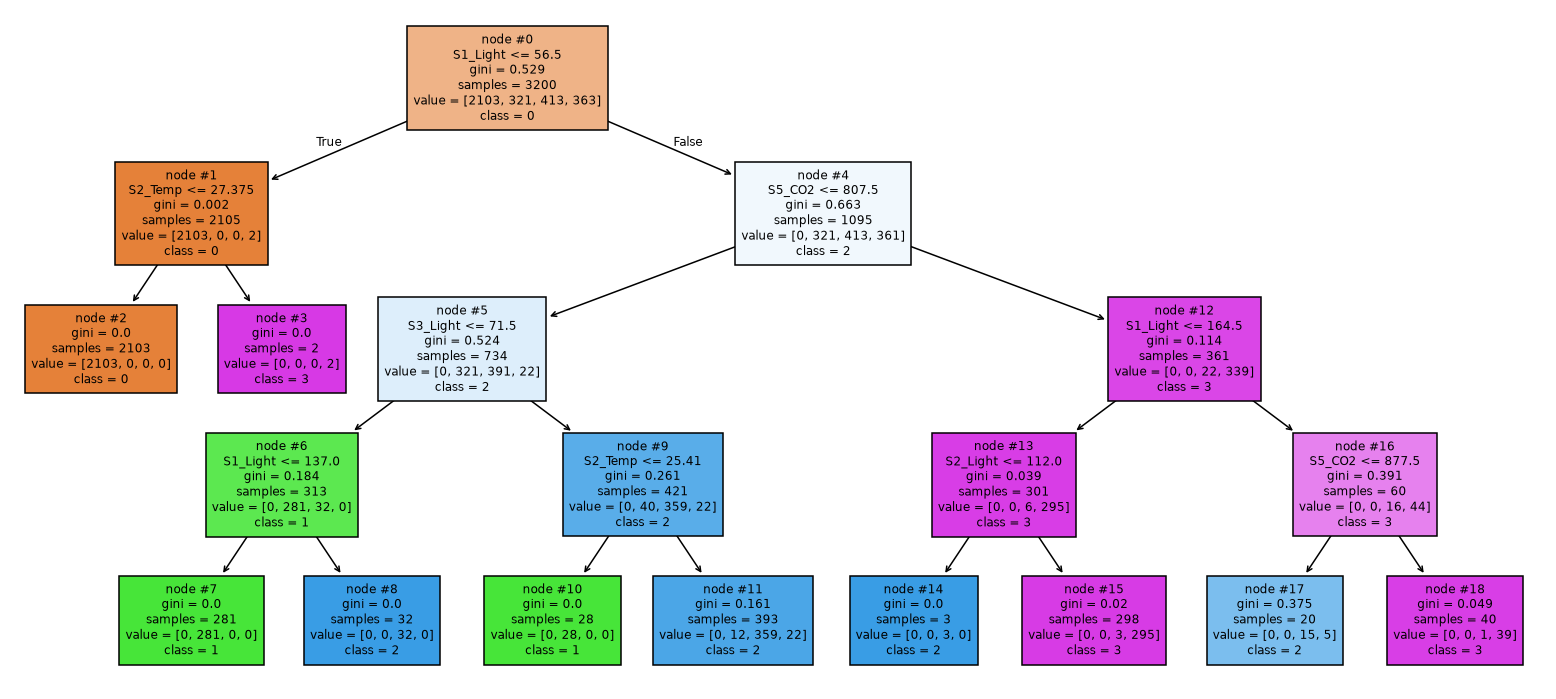

In [56]:
plt.figure(figsize=(18, 8))
plot_tree(tree_A, feature_names=cols_A, class_names=["0", "1", "2", "3"],
          node_ids=True, filled=True, fontsize=8)
plt.show()

## 8.3 - Candidate B: a tree on aggregated sensors

We saw in part 3 that sensors of the same type were probably strongly correlated. Therefore, we had the idea of aggregating them all together and try to make a tree out of them. 

Here are all the new variables we built and how we built them.

| New variable | Formula |
|---|---|
| temp_mean | mean of S1 to S4 temperature |
| light_mean | mean of S1 to S4 light |
| sound_max | max of S1 to S4 sound |
| S5_CO2, S5_CO2_Slope | kept as they are |
| PIR_sum | S6_PIR + S7_PIR (0, 1 or 2 detectors see movement) |


In [57]:
cols_B = ["temp_mean", "light_mean", "sound_max", "S5_CO2", "S5_CO2_Slope", "PIR_sum"]

def aggregate(X):
    """Build the 6 aggregated sensors from the 16 raw sensors (fixed formulas, no learning)"""
    return pd.DataFrame({
        "temp_mean": X[["S1_Temp", "S2_Temp", "S3_Temp", "S4_Temp"]].mean(axis=1),
        "light_mean": X[["S1_Light", "S2_Light", "S3_Light", "S4_Light"]].mean(axis=1),
        "sound_max": X[["S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound"]].max(axis=1),
        "S5_CO2": X["S5_CO2"],
        "S5_CO2_Slope": X["S5_CO2_Slope"],
        "PIR_sum": X["S6_PIR"] + X["S7_PIR"],
    }, index=X.index)

tree_B, params_B, grid_B = tune_tree(aggregate(Xtr), aggregate(Xva))
print("Best settings for B:", params_B)
grid_B.sort_values("regret").head(5).round(3)

Best settings for B: {'max_depth': 8, 'min_samples_leaf': 1}


,max_depth,min_samples_leaf,accuracy,macro_F1,mean_cost,regret
30,8,1,0.915,0.759,0.566,0.085
35,10,1,0.915,0.759,0.566,0.085
9,2,50,0.905,0.608,0.575,0.095
7,2,10,0.905,0.608,0.575,0.095
6,2,5,0.905,0.608,0.575,0.095


This has acceptable performances, especially with the low regret, however its performance is worse and the best trees are deeper that the ones we had with the unaggregated features. This probably means that some sensors are more important than others, and thus, that by aggregating the features together, we are diluting information instead of grouping it together.

We will thus continue our experiments keeping the features separated.

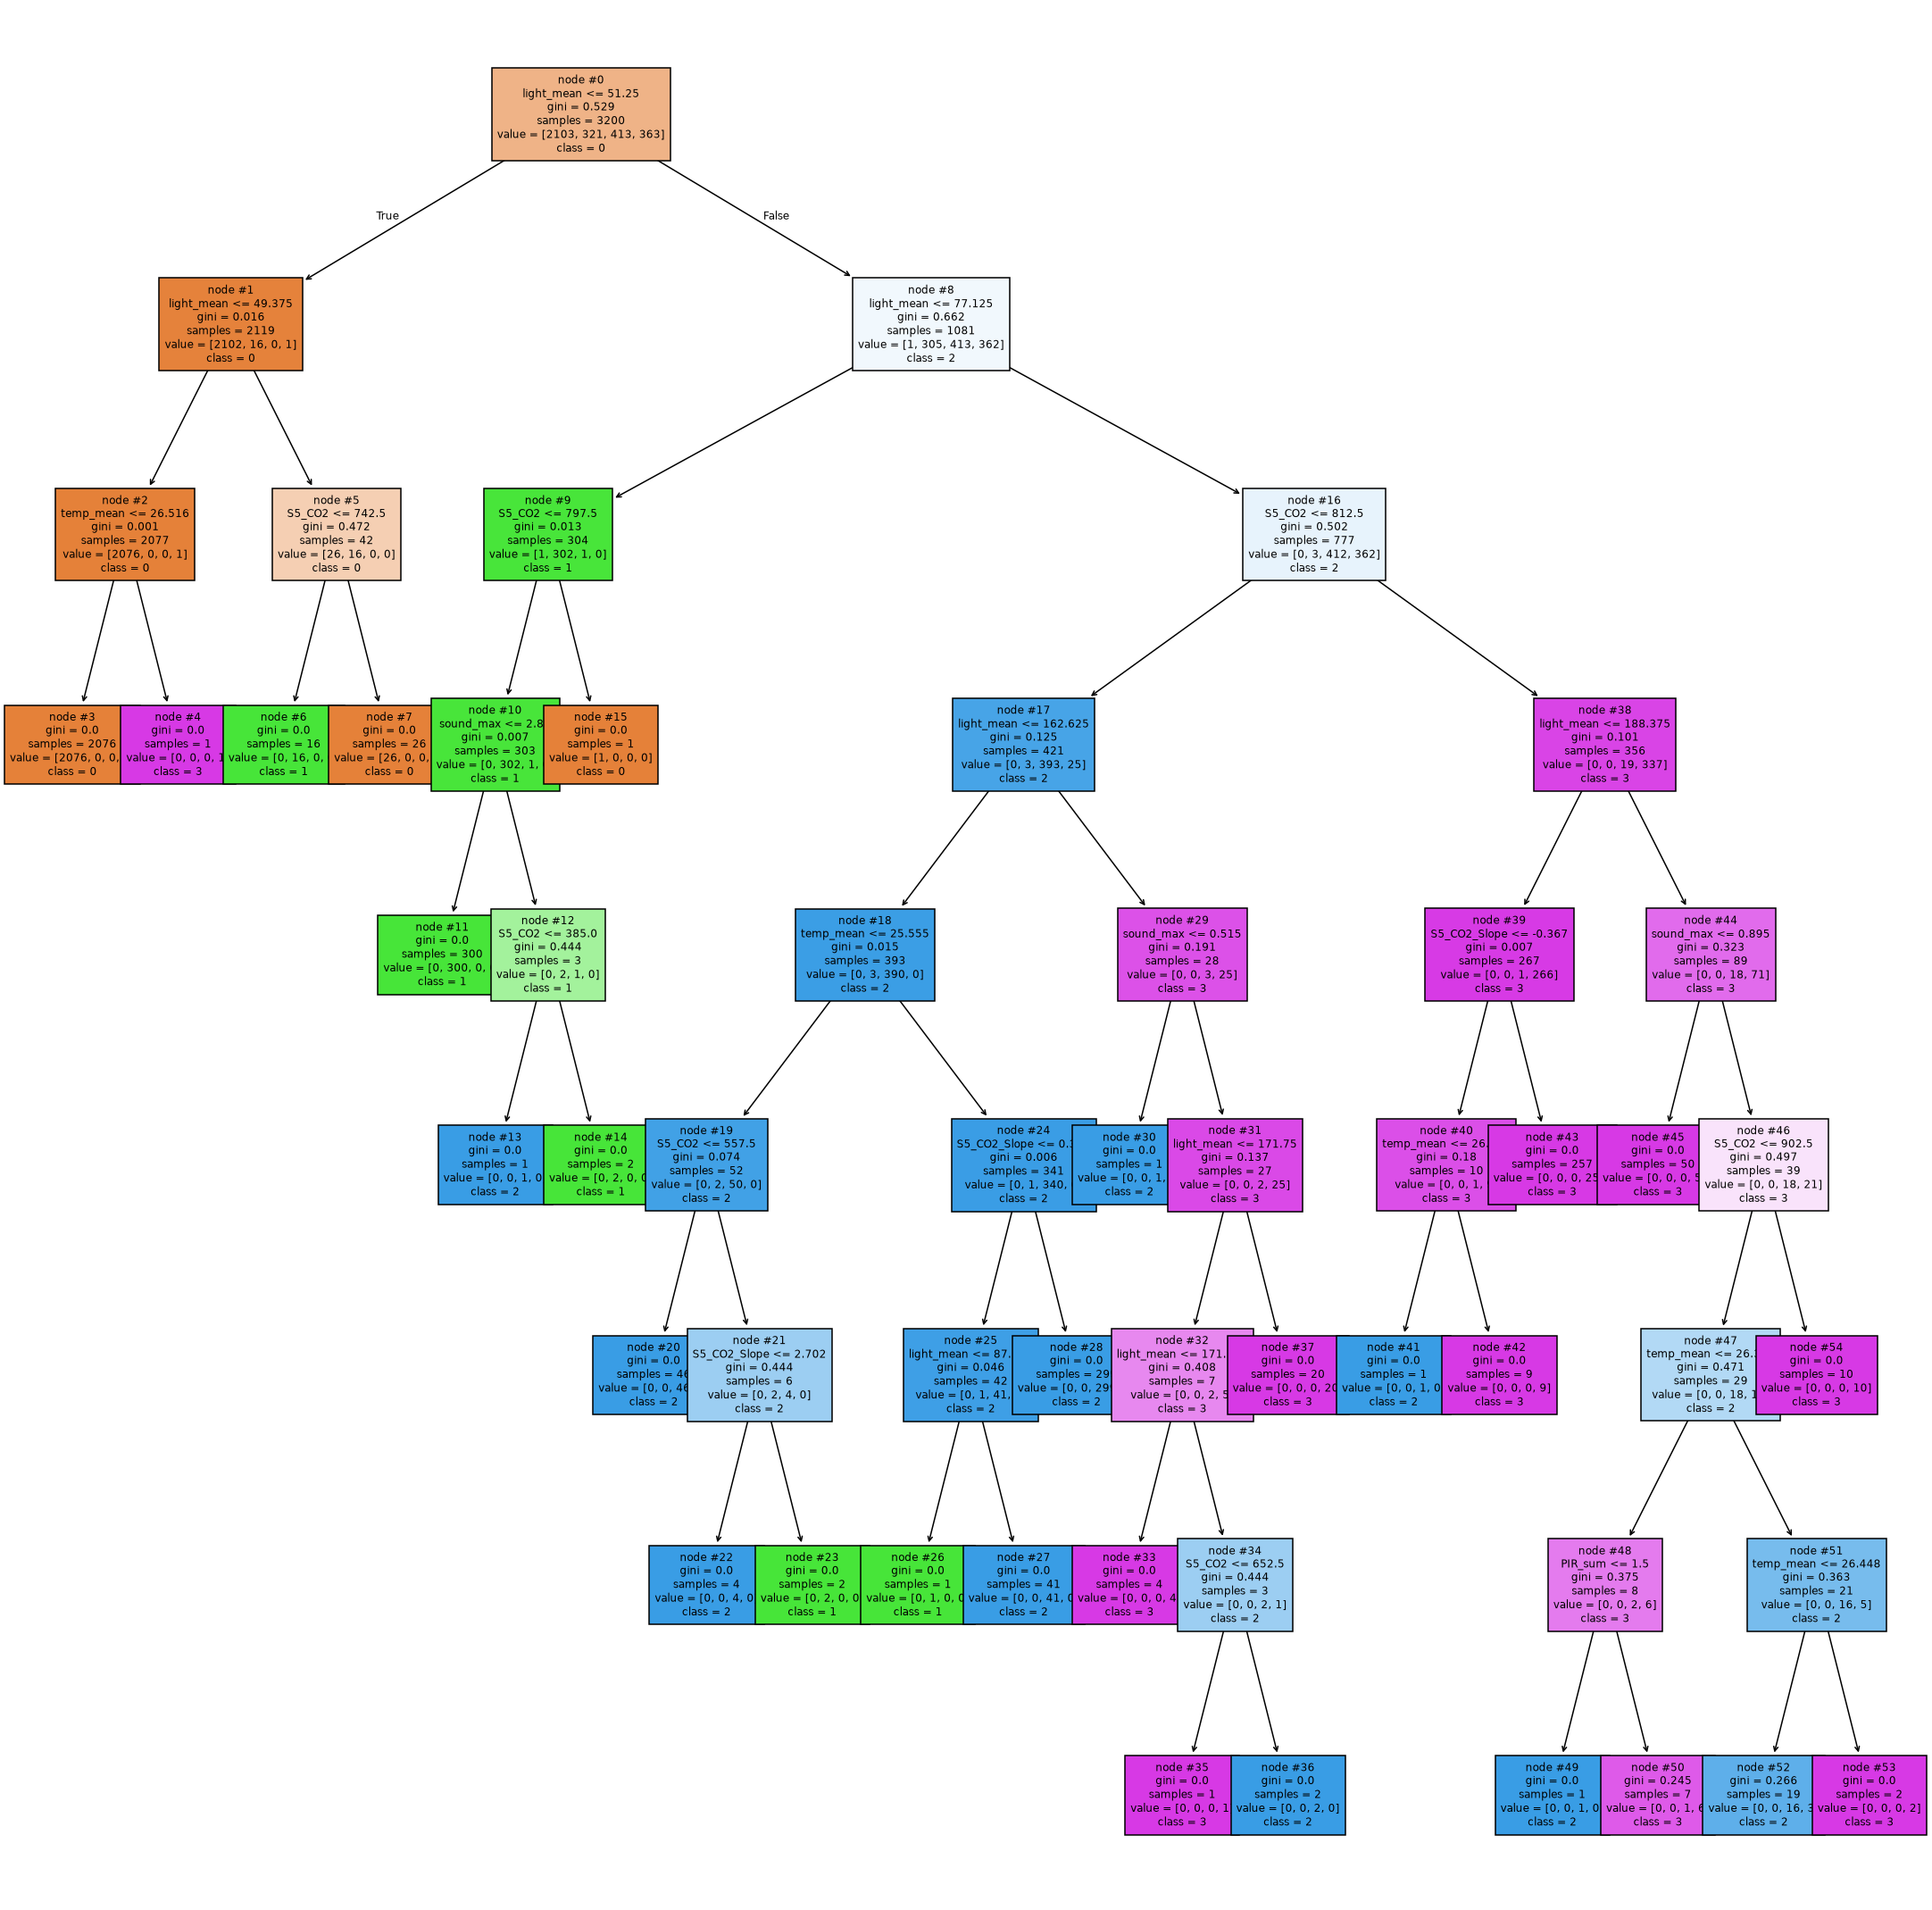

In [58]:
plt.figure(figsize=(25, 25))
plot_tree(tree_B, feature_names=cols_B, class_names=["0", "1", "2", "3"],
          node_ids=True, filled=True, fontsize=8)
plt.show()

## 8.4 - Candidate C: forward selection on the raw sensors

Now, what de want to test is feature selection. To do so, we start by doing forward feature selection as seen in class. We start with no sensor and add them **one at a time**. At each step we add the sensor that gives the lowest mean cost on the **train** data. If two sensors give the same cost, the one with the lower log-loss wins.

This gives a **path**: the best sensor, then the best pair, and so on.

After that, for each length k of the path (1 to 16 sensors), we tune a tree with the tree function defined earlier and look at the validation regret. We keep the k with the lowest validation regret (and the smallest k if there is a tie).

In [59]:
PATH_TREE = {"max_depth": 3, "min_samples_leaf": 20, "random_state": 0}   # small fixed tree to test only one sensor at a time, in order not to dilute the information, and really know which feature adds the information

def train_cost_logloss(cols):
    """Mean cost and log-loss on the train part, for the small fixed tree on these columns"""
    tree = DecisionTreeClassifier(**PATH_TREE).fit(Xtr[cols], ytr)
    P = tree_proba(tree, Xtr[cols])
    cost = mean_cost(action(P), ytr)
    p_true = np.clip(P[np.arange(len(ytr)), ytr], 1e-6, 1 - 1e-6)   # probability given to the true count
    return cost, -np.mean(np.log(p_true))

forward_path, path_steps = [], []
for step in range(16):
    tries = []
    for f in features:
        if f not in forward_path:
            cost, logloss = train_cost_logloss(forward_path + [f])
            tries.append((round(cost, 10), logloss, f))
    cost, logloss, best_f = min(tries)   # lowest cost first, then lowest log-loss
    forward_path.append(best_f)
    path_steps.append({"k": step + 1, "added": best_f, "train_cost": cost, "train_logloss": logloss})

pd.DataFrame(path_steps).round(4)


,k,added,train_cost,train_logloss
0,1,S1_Light,0.7647,0.1388
1,2,S1_Temp,0.7347,0.0959
2,3,S2_Light,0.7344,0.0946
3,4,S1_Sound,0.7344,0.0941
4,5,S2_Sound,0.7344,0.0941
5,6,S2_Temp,0.7344,0.0941
6,7,S3_Sound,0.7344,0.0941
7,8,S4_Light,0.7344,0.0941
8,9,S4_Sound,0.7344,0.0941
9,10,S4_Temp,0.7344,0.0941


Here we see that after the third sensor, the training cost stops changing 0.7344. The log-loss only improves very slightly when S1_Sound is added (from 0.0946 to 0.0941). Then, from k = 4 to k = 13, both stay exactly the same. We therefore understand that the small path tree does not use the other sensors: they add no new information to its splits. At k = 14, adding S5_CO2 actually makes the training cost and the log-loss go up: adding these sensors is detrimental to our cost. 

In [60]:
# for each length k of the path: tune the tree, then look at the regret on train and on validation
forward_rows, forward_trees = [], {}
for k in range(1, 17):
    tree, params, _ = tune_tree(Xtr[forward_path[:k]], Xva[forward_path[:k]])
    forward_trees[k] = (tree, params)
    forward_rows.append({"k": k, **params,
                         "train_regret": evaluate(tree, Xtr[forward_path[:k]], ytr)["regret"],
                         "val_regret": evaluate(tree, Xva[forward_path[:k]], yva)["regret"]})
forward_table = pd.DataFrame(forward_rows)

# lowest validation regret and smallest k if there is a tie
forward_table["val_r"] = forward_table["val_regret"].round(10)
k_C = int(forward_table.sort_values(["val_r", "k"]).iloc[0]["k"])
forward_table = forward_table.drop(columns="val_r")

cols_C = forward_path[:k_C]
tree_C, params_C = forward_trees[k_C]
print("Chosen k:", k_C, "->", cols_C)
print("Best settings for C:", params_C)
forward_table.round(3)

Chosen k: 3 -> ['S1_Light', 'S1_Temp', 'S2_Light']
Best settings for C: {'max_depth': 5, 'min_samples_leaf': 20}


,k,max_depth,min_samples_leaf,train_regret,val_regret
0,1,3,50,0.066,0.045
1,2,5,20,0.026,0.001
2,3,5,20,0.025,0.000
3,4,5,20,0.025,0.000
4,5,5,20,0.025,0.000
5,6,5,20,0.022,0.000
6,7,5,20,0.017,0.000
7,8,3,50,0.036,0.001
8,9,3,50,0.036,0.001
9,10,3,50,0.036,0.001


Since the regret is the same for k = 3 to 7, our tie rule keeps the smallest tree: k = 3, with S1_Light, S1_Temp and S2_Light. 
We see that adding S1_Sound improves the training log-loss a little, but it does not improve the validation regret, so we do not keep it. 

With these 3 sensors, the tree (depth 5, at least 20 rows per leaf) reaches a validation regret close to 0, lower than candidate A (0.017) with all 16 sensors (which we can also see at the last row of our tree table, since it also has all 16 features)

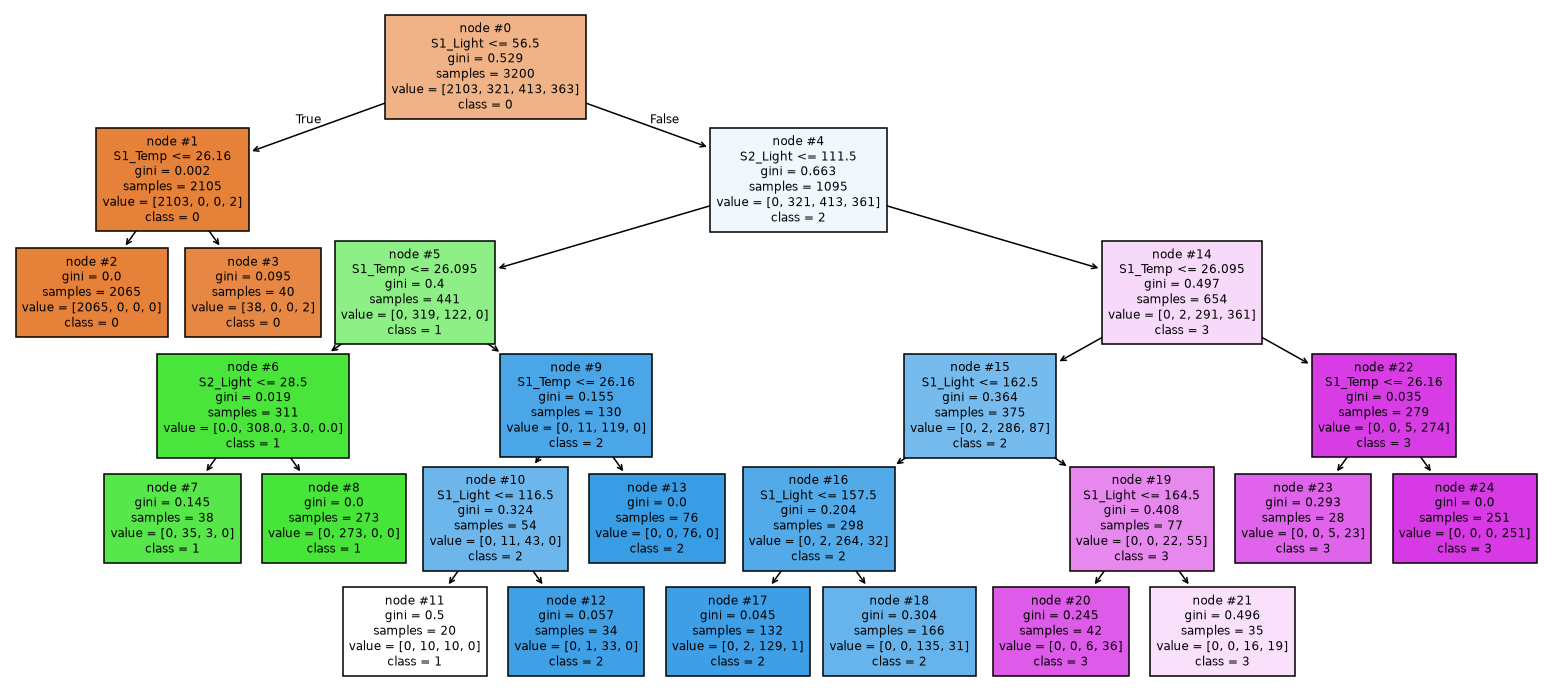

In [61]:
plt.figure(figsize=(18, 8))
plot_tree(tree_C, feature_names=cols_C, class_names=["0", "1", "2", "3"],
          node_ids=True, filled=True, fontsize=8)
plt.show()

## 8.5 - Candidate D: LASSO selection on the raw sensors

Now, instead of doing forward feature selection, we want to try doing LASSO selection on the sensors.

To do so we treat the number of people as a number (0 to 3) and predict it with a linear formula.
We standardise each sensor with the **mean and standard deviation of the train part only**, and we centre the target with its train mean (so no intercept is needed).
We try 50 values of λ (the penalisation coef) between 0.0001 and 1, and choose λ with the lowest **validation MSE** (on the predicted number of people).
**The LASSO is only used to choose sensors**, and after the selection, a decision tree is trained on the selected raw sensors and gives the probabilities.

In [62]:
mu, sd = Xtr[features].mean(), Xtr[features].std(ddof=0)   # statistics of the train data
Ztr = (Xtr[features] - mu) / sd
Zva = (Xva[features] - mu) / sd
y_mean = ytr.mean()                                          # train mean of the target

lams = np.logspace(-4, 0, 50)
coefs, val_mse = [], []
for lam in lams:
    lasso = Lasso(alpha=lam, fit_intercept=False, tol=1e-9, max_iter=100000).fit(Ztr, ytr - y_mean)
    coefs.append(lasso.coef_)
    val_mse.append(np.mean((lasso.predict(Zva) + y_mean - yva) ** 2))   # add back the train mean
coefs, val_mse = np.array(coefs), np.array(val_mse)

i_best = int(np.argmin(val_mse))   # first minimum = smallest lam if there is a tie
lam_D = float(lams[i_best])
cols_D = [f for f, c in zip(features, coefs[i_best]) if abs(c) > 1e-8]
print(f"Chosen lam: {lam_D:.5f}  (validation MSE = {val_mse[i_best]:.4f})")
if len(cols_D) == 0:
    print("LASSO selected no sensor, so we keep all 16 sensors for candidate D")
    cols_D = list(features)
print(len(cols_D), "selected sensors:", cols_D)

Chosen lam: 0.00037  (validation MSE = 0.0014)
14 selected sensors: ['S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']


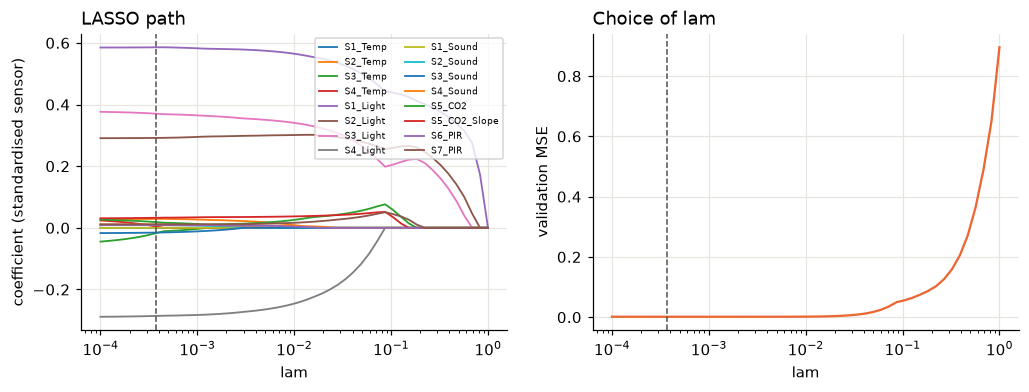

In [63]:
# 1: oefficient of each sensor for each penalisation factor lam
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
for j, f in enumerate(features):
    ax1.plot(lams, coefs[:, j], lw=1.2, label=f)
ax1.set_xscale("log")
ax1.set_xlabel("lam")
ax1.set_ylabel("coefficient (standardised sensor)")
ax1.set_title("LASSO path", loc="left")
ax1.legend(fontsize=6, ncol=2, loc="upper right")

# 2: Val mse for all pen fct lam 
ax2.plot(lams, val_mse, color=ORANGE)
ax2.set_xscale("log")
ax2.set_xlabel("lam")
ax2.set_ylabel("validation MSE")
ax2.set_title("Choice of lam", loc="left")
for ax in (ax1, ax2):
    ax.axvline(lam_D, color=GREY, ls="--", lw=1)
plt.show()


In [64]:
tree_D, params_D, grid_D = tune_tree(Xtr[cols_D], Xva[cols_D])
print("Best settings for D:", params_D)
grid_D.sort_values("regret").head(5).round(3)

Best settings for D: {'max_depth': 4, 'min_samples_leaf': 1}


,max_depth,min_samples_leaf,accuracy,macro_F1,mean_cost,regret
20,5,1,0.983,0.945,0.497,0.017
15,4,1,0.983,0.945,0.497,0.017
25,6,1,0.983,0.945,0.497,0.017
35,10,1,0.983,0.944,0.498,0.017
30,8,1,0.983,0.944,0.498,0.017


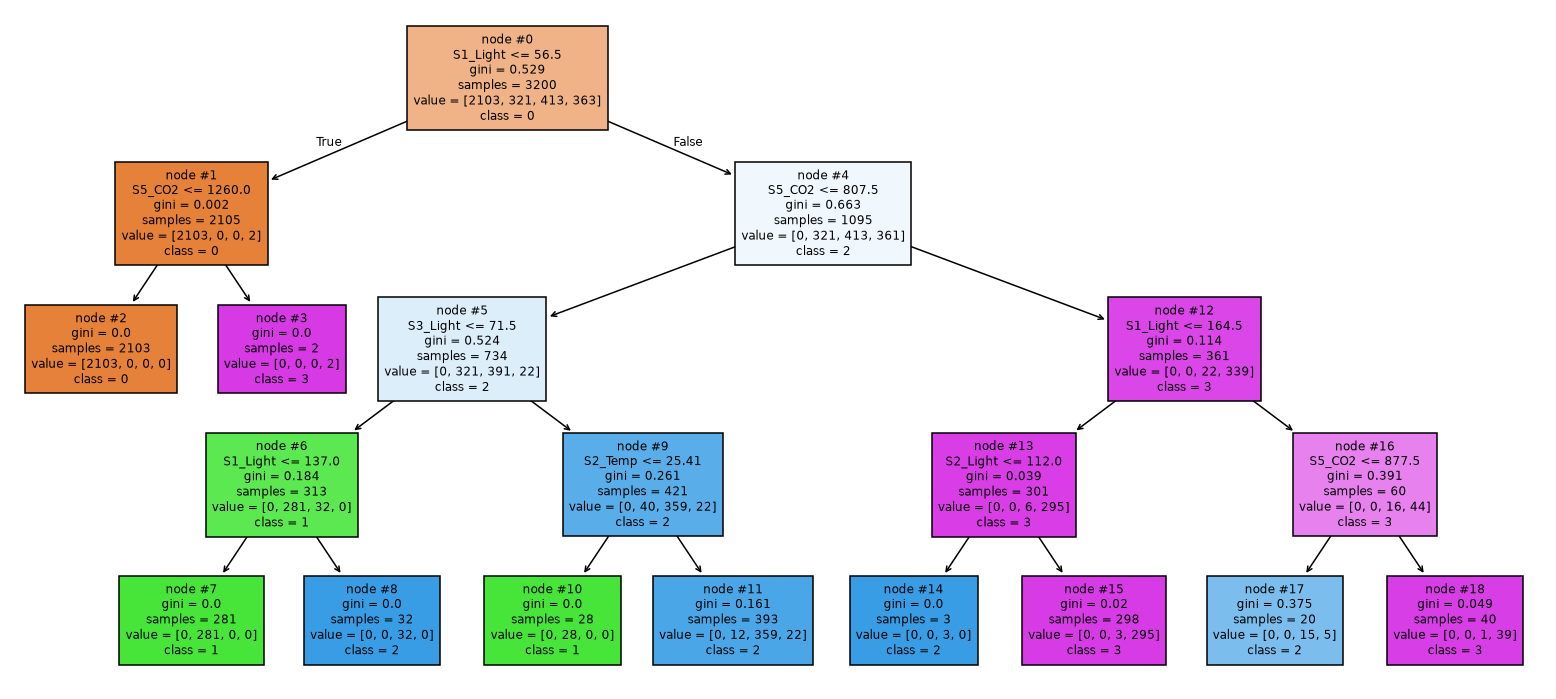

In [65]:
plt.figure(figsize=(18, 8))
plot_tree(tree_D, feature_names=cols_D, class_names=["0", "1", "2", "3"],
          node_ids=True, filled=True, fontsize=8)
plt.show()

# 9 - Comparison on validation

We compare the 2 baselines and the 4 candidates on the **validation** data to select our final model.
Our final candidate is the one with the **lowest validation regret** (and the one with fewer sensors if there is a tie)

Then we save all the choices in the file `frozen_choices.json` !

In [66]:
def raw(X):
    """The raw sensors"""
    return X

# for each candidate: its tree, its var, its settings, and how to build its inputs from the raw sensors
candidates = {
    "A: tree, 16 raw sensors": (tree_A, cols_A, params_A, raw),
    "B: tree, 6 aggregated sensors": (tree_B, cols_B, params_B, aggregate),
    "C: tree, forward selection": (tree_C, cols_C, params_C, raw),
    "D: tree, LASSO selection": (tree_D, cols_D, params_D, raw),
}

rows = {}
for name, s in baselines.iterrows():   # the 2 baselines use no sensor
    rows[name] = {"n_variables": 0, **s.to_dict(), "max_depth": "-", "min_samples_leaf": "-"}
for name, (tree, cols, params, prep) in candidates.items():
    rows[name] = {"n_variables": len(cols), **evaluate(tree, prep(Xva)[cols], yva), **params}
comparison = pd.DataFrame.from_dict(rows, orient="index")
comparison["other"] = "-"
comparison.loc["C: tree, forward selection", "other"] = f"k = {k_C}"
comparison.loc["D: tree, LASSO selection", "other"] = f"lam = {lam_D:.5f}"
comparison.round(3)

,n_variables,accuracy,macro_F1,mean_cost,regret,max_depth,min_samples_leaf,other
Never ventilate (always predict 0),0,0.758,0.216,0.962,0.481,-,-,-
Always ventilate for 3,0,0.062,0.029,3.000,2.519,-,-,-
"A: tree, 16 raw sensors",16,0.983,0.945,0.497,0.017,4,1,-
"B: tree, 6 aggregated sensors",6,0.915,0.759,0.566,0.085,8,1,-
"C: tree, forward selection",3,1.000,0.999,0.481,0.000,5,20,k = 3
"D: tree, LASSO selection",14,0.983,0.945,0.497,0.017,4,1,lam = 0.00037


In [67]:
# final choiceee
ranking = comparison.loc[list(candidates)].copy()
ranking["regret_r"] = ranking["regret"].astype(float).round(10)
final_name = ranking.sort_values(["regret_r", "n_variables"]).index[0]
final_tree, final_cols, final_params, final_prep = candidates[final_name]
print("Final candidate (chosen on validation only):", final_name)

frozen = {
    "final_candidate": final_name,
    "final_variables": final_cols,
    "final_hyperparameters": final_params,
    "lasso_lam": lam_D,
    "forward_path": forward_path,
    "forward_k": k_C,
    "all_candidates": {name: {"variables": cols, "hyperparameters": params}
                       for name, (tree, cols, params, prep) in candidates.items()},
}
with open("saved_choices.json", "w") as f:
    json.dump(frozen, f, indent=2)

choices_frozen = True
print("Choices saved in saved_choices.json")

Final candidate (chosen on validation only): C: tree, forward selection
Choices saved in saved_choices.json


On validation regret, we have chosen to keep candidate C (forward selection, with only 3 sensors: `S1_Light`, `S1_Temp`, `S2_Light`). Indeed, it has the lowest regret (0.0005, almost perfect). The LASSO keeps 14 of the 16 sensors, so D is almost the same tree as A. And we can indeed see that they have similar performance over the validation data. B (aggregated sensors) is the weakest of the four (regret 0.085), but all four beat the two baselines.
C is our final choice so we save it before performing the test !

# 10 - Test

We now use the test data !

One thing to keep in mind is that the test data has no row with exactly 1 person. If a model predicts "1 person" on the test, class 1 gets an F1 of 0 and pulls the macro-F1 down; if it never does, class 1 is left out of the average.
So the macro-F1 on the test is not really reliable and cannot be compared with the validation: the regret is our main measure here.


In [68]:
print("Candidate chosen BEFORE the test:", final_name)

test_rows = {
    "Never ventilate (always predict 0)": {"n_variables": 0, **scores(yte, np.zeros_like(yte), np.zeros_like(yte))},
    "Always ventilate for 3": {"n_variables": 0, **scores(yte, np.full_like(yte, 3), np.full_like(yte, 3))},
}
for name, (tree, cols, params, prep) in candidates.items():
    test_rows[name] = {"n_variables": len(cols), **evaluate(tree, prep(Xte)[cols], yte)}
test_table = pd.DataFrame.from_dict(test_rows, orient="index")
test_table["chosen before test"] = ["yes" if n == final_name else "" for n in test_table.index]
test_table.round(3)


Candidate chosen BEFORE the test: C: tree, forward selection


,n_variables,accuracy,macro_F1,mean_cost,regret,chosen before test
Never ventilate (always predict 0),0,0.939,0.323,0.327,0.164,
Always ventilate for 3,0,0.042,0.027,3.000,2.836,
"A: tree, 16 raw sensors",16,0.944,0.436,0.296,0.133,
"B: tree, 6 aggregated sensors",6,0.947,0.495,0.293,0.130,
"C: tree, forward selection",3,0.958,0.632,0.282,0.118,yes
"D: tree, LASSO selection",14,0.944,0.436,0.296,0.133,


In [69]:
# Confusion matrix of the chosen candidate: true number of people (rows) vs ventilation level chosen (columns)
final_actions = action(tree_proba(final_tree, final_prep(Xte)[final_cols]))
cm = confusion_matrix(yte, final_actions, labels=CLASSES)
pd.DataFrame(cm, index=[f"true y={y}" for y in CLASSES], columns=[f"action a={a}" for a in CLASSES])

,action a=0,action a=1,action a=2,action a=3
true y=0,4530,0,0,0
true y=1,0,0,0,0
true y=2,0,0,93,0
true y=3,184,0,17,0


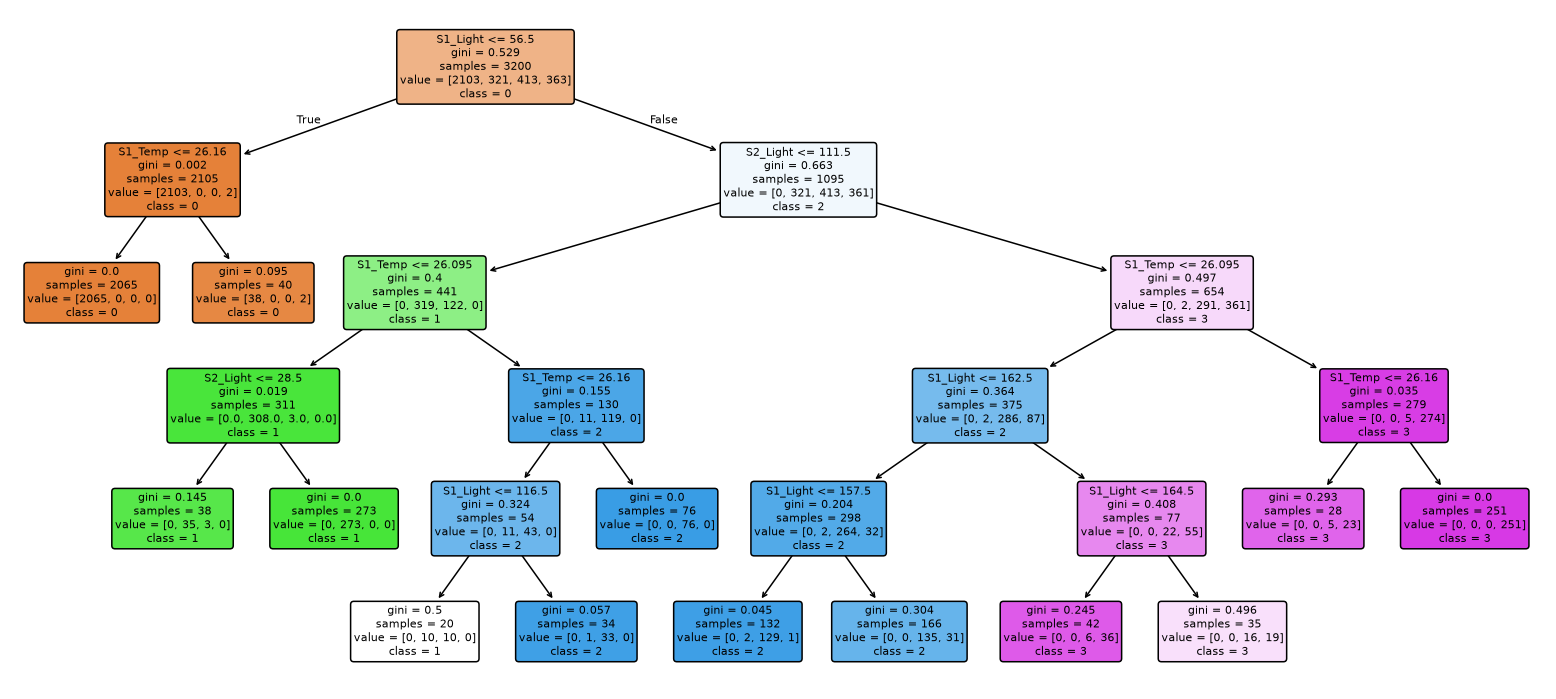

In [70]:
# We draw the final tree
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(final_tree, feature_names=final_cols, class_names=[str(c) for c in CLASSES],
            filled=True, rounded=True, fontsize=7, ax=ax)
plt.show()


After our test, we see that C stays the best candidate (with a regret of 0.118), ahead of B (0.130), A and D (0.133), and the "never ventilate" baseline (0.164). It is interesting to see here that B comes back with a lower regret, even though on training data, it was far behind the others. Maybe on data taken on a longer time period, it would produce even better results.

However, we see on the confusion matrix that in 184 rows with 3 people the tree chose level 0 (no air). These rows are on 10 Jan between 15:25 and 17:00: 3 people were in the room but lights S1 and S2 were almost off (about 7 lux, against about 150 to 240 lux with 3 people in train). The chosen tree uses mostly the light sensors, so it thinks the room is empty. This never happened in the 1.5 days of training, which shows some limits to choosing sensors on such a short period.